# Price tier prediction

A multiclass classification problem, aimed for predicting price tier of a work place with respect to its features set,
using simple ways to workwith complete end to end machine learning pipeline for making this sytem work. Dataset details,
walk through with complete roadmap with learning machine learning hands on.

**Real Life usecase**
Model is scoped stricly for academic purpose, But could be used in several ways
+ Working as ranking list engine for automated price prediction through scraped details about workspace
+ Listing strongness of work places with our own listing index
+ commercializing listing and improvement directions for workspace for our index range

Thus model could be integrated for a application for companies to manage there hybrid offices location.
rest core architechture and learning could be expanded for soo many problem scope.

In [162]:
# GLOBAL PARAMETERS

TRAIN_PATH = '/home/madhav/workstation/Lab/experiment/data/MLP-PROJECT-DATASET/train.csv'
TEST_PATH = 'experiment/data/MLP-PROJECT-DATASET/test.csv'

# MODEL CONFIGS

## Exploratory data analysis

We would explore dataset with univariate approach with both categorical and numerical, 
implementing simple binning and aggregation perspective with dataset we would broadly follow simple rules

Simple univarite exploration
+ Plot univariate unit with single distribution
+ Plot the relation between target value with the feature of interest

In [163]:
# Basic data exploration
import pandas as pd 

df = pd.read_csv(TRAIN_PATH)

# Utility function for targeted relation plot

def relation_ploter(relation, size):
    ''' 
    Makes targeted distribution plot with alligned group df element
    relation_dataframe[grouping_element].groupby('price_tier')
    '''
    # Relation ploting tool
    fig, ax = plt.subplots(
        1, size, figsize=(15,2),
        layout='tight'
    )

    for i, (space_class, group_series) in enumerate(relation.groupby(level=0)):
        price_tier_counts = group_series.droplevel(0)
        price_tier_counts = price_tier_counts.sort_index()

        price_tier_counts.plot(
            kind='bar',
            ax=ax[i],
            color='darkblue',
            edgecolor='black'
        )
        ax[i].set_title(space_class)
        ax[i].set_xlabel("Target Class")
        ax[i].set_ylabel("Count")
        ax[i].tick_params(axis='x', rotation=0) # Keep x-labels upright


df.info()

<class 'pandas.DataFrame'>
RangeIndex: 279746 entries, 0 to 279745
Data columns (total 60 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   space_id                      279746 non-null  int64  
 1   operator_ref                  279142 non-null  str    
 2   operator_platform_age_years   279142 non-null  float64
 3   operator_platform_age_months  279142 non-null  float64
 4   operator_active_years         279140 non-null  float64
 5   operator_active_months        279140 non-null  float64
 6   operator_class                279746 non-null  str    
 7   operator_certified            279142 non-null  str    
 8   operator_portfolio_size       279142 non-null  float64
 9   operator_has_avatar           279142 non-null  str    
 10  operator_id_verified          279142 non-null  str    
 11  zone                          279746 non-null  str    
 12  borough                       65295 non-null   str    


Distribution of potential categorical | high cardinal feature


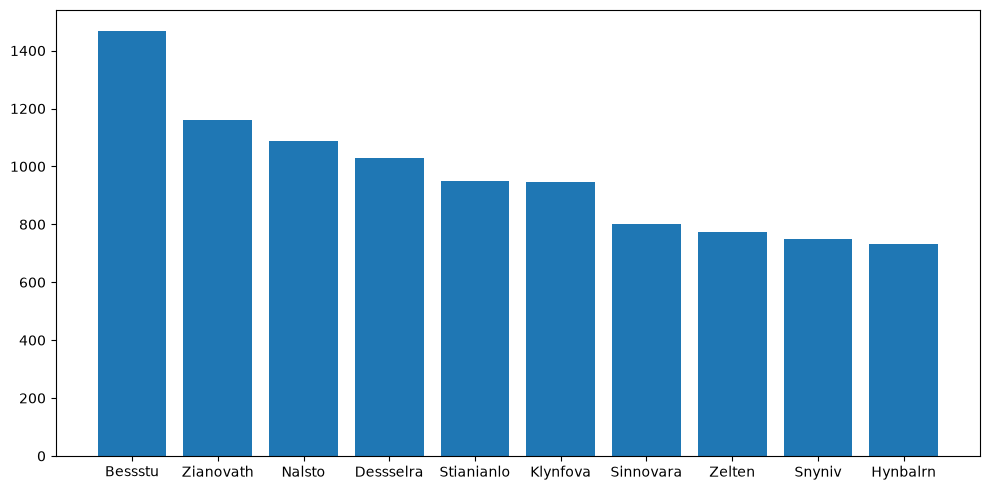

In [164]:
'''
Targeted variable for exploration
operator_ref, operator_class, space_class

Kernel Crash during plot
With 41 thousand reference unique,
we cant direct plot those numbers

Potential dropout with operator_ref
covering with 14 percent on total dataset size

Potential imputation with distribution of these refrences
with other based binning for rest of non-common elements
'''
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

ref_data = df.loc[:, 'operator_ref'].dropna()

# top 10 ranker of referals
rankers = ref_data.value_counts()[:10]
plt.figure(figsize=(10,5))
plt.bar(
    rankers.index, 
    rankers,
    width=0.8
)
plt.tight_layout()
print("Distribution of potential categorical | high cardinal feature")

feature scope : <StringArray>
['independent_operator', 'unverified_operator', 'managed_operator']
Length: 3, dtype: str


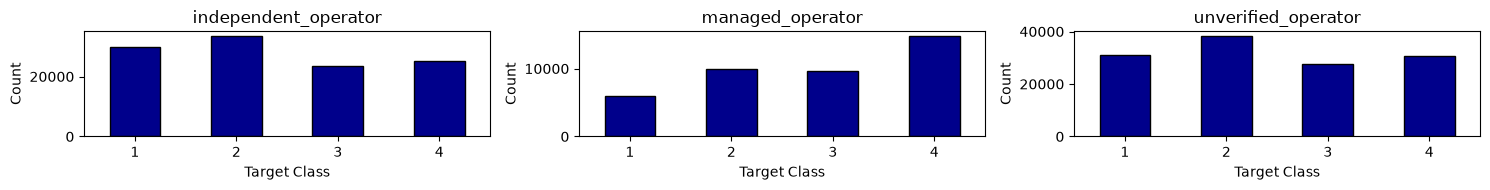

In [165]:
# Target : oprator_class

feature = df['operator_class'].dropna()
scope = feature.unique()
print(f"feature scope : {scope}")

# How is the all three classes are distributed ?
distribution = feature.value_counts()

# what is the relation of operator_class with target feature ?
relation = df.groupby('operator_class')['price_tier'].value_counts().sort_values()

relation_ploter(relation, size=3)

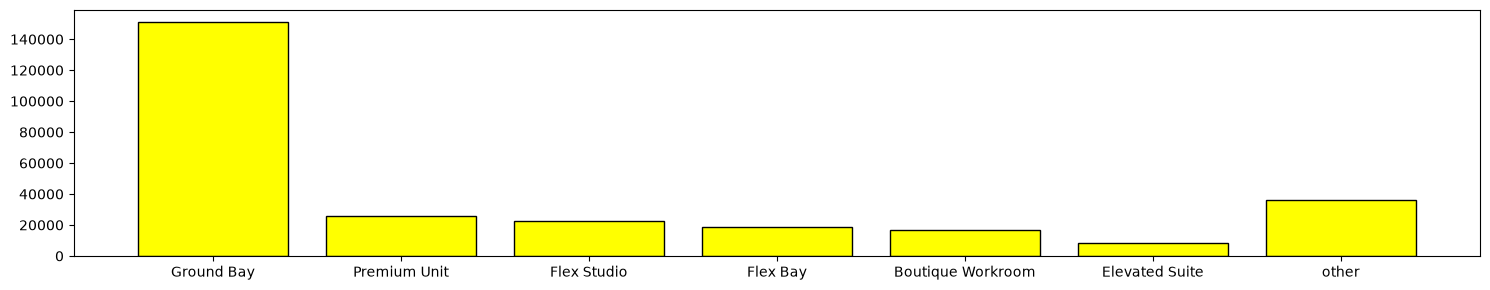

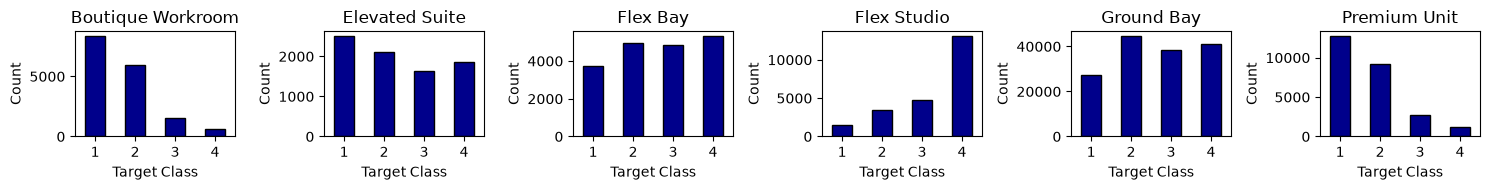

In [176]:
# Exploring space class distribution

feature = df['space_class'].dropna()
#print(f"Looking with distribution of the values with class : {feature.unique()}")

size = 6
# Grouping elements with value counting ranking
values = feature.value_counts(ascending=False)

# top ranker data
rankers = list(values.index[:size])
freq = list(values[:size])

# Leading other bin
other_sum = values[size:].sum()
rankers.append('other')

freq.append(other_sum)
plt.figure(figsize=(15,3))
plt.bar(
    x=rankers,
    height=freq,
    color='yellow',
    edgecolor='black'
)
plt.tight_layout()

# realtion of feature rankers with price tier
space_classing = df[
    df['space_class'].isin(rankers[:-1])
]

space_class_relation = space_classing.groupby(
    'space_class'
)['price_tier'].value_counts()

relation_ploter(space_class_relation, size=size)

### Categorical dataset exploration report

With given set of features, we can see some really nice insights about picked features,
operator_ref contains really big number of elements which makes it non-ideal for seting up with one-hot encoding, dataset contains high variability, along with thousand of features, thus in first place it looked as promising feature to have but now its leaning towards droping

With `operator_class` we assumed to have good directive distribution with the target feature where it contains slight featuring with target features. we would approach for making its onehot encoding through which model might benifit with its certain neiche distribution pattern we see in plot

With space_class distribution plot we can see really strong pattern of followup, features are trending with one perticular class with perticular space class, which is really good for making them with targeted encoding for featuring them into the next plot with OneHot encoding set.